In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
fieldwork_heights = pd.read_csv("lizirias_fieldwork_20260707.csv")
fieldwork_heights.head()

,plot_id,tree_id,d_cm,pap_cm,ct_mm,ht_m,hcb_m,yd,papi,di,...,ctj,ctk,species,observations,Unnamed: 18,Unnamed: 19,area1,area2,area3,d_est
0,10,1,15.406198,48.4,NaN,5.1,1.9,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN
1,10,2,46.700000,NaN,22.0,10.4,2.5,NaN,NaN,NaN,...,NaN,NaN,Sb,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,3,63.800000,NaN,25.0,10.0,3.2,NaN,NaN,NaN,...,NaN,NaN,Sb,Damaged bark,NaN,NaN,NaN,NaN,NaN,NaN
3,10,4,13.528170,42.5,NaN,5.4,1.8,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN
4,10,5,20.849298,65.5,NaN,6.9,1.9,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN


- Remove the trees which have diameters (d_cm) lower than 7.5cm, 
- check this distribution of heights
- use this to determine the shortest trees to survey

In [4]:
fieldwork_heights = fieldwork_heights[fieldwork_heights['d_cm'] >= 7.5]
fieldwork_heights.head()

,plot_id,tree_id,d_cm,pap_cm,ct_mm,ht_m,hcb_m,yd,papi,di,...,ctj,ctk,species,observations,Unnamed: 18,Unnamed: 19,area1,area2,area3,d_est
0,10,1,15.406198,48.4,NaN,5.1,1.9,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN
1,10,2,46.700000,NaN,22.0,10.4,2.5,NaN,NaN,NaN,...,NaN,NaN,Sb,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,3,63.800000,NaN,25.0,10.0,3.2,NaN,NaN,NaN,...,NaN,NaN,Sb,Damaged bark,NaN,NaN,NaN,NaN,NaN,NaN
3,10,4,13.528170,42.5,NaN,5.4,1.8,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN
4,10,5,20.849298,65.5,NaN,6.9,1.9,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN


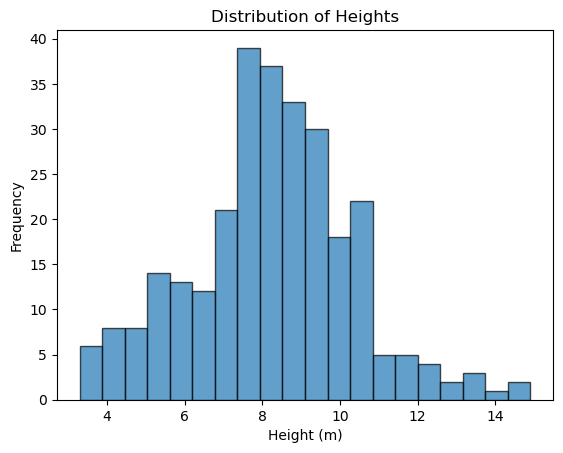

In [5]:

plt.hist(fieldwork_heights['ht_m'], bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('Height (m)')
plt.ylabel('Frequency')
plt.title('Distribution of Heights')
plt.show()

In [6]:
fieldwork_heights['ht_m'].min()

np.float64(3.3)

This finds the minimum tree height (of the maximum height from fieldwork) is 3.3m. 

Check distribution of hcb_m, to determine the height to begin the chm mask. This is so the mask captures as much of the crowns as possible, to ensure accurate crown area predictions 

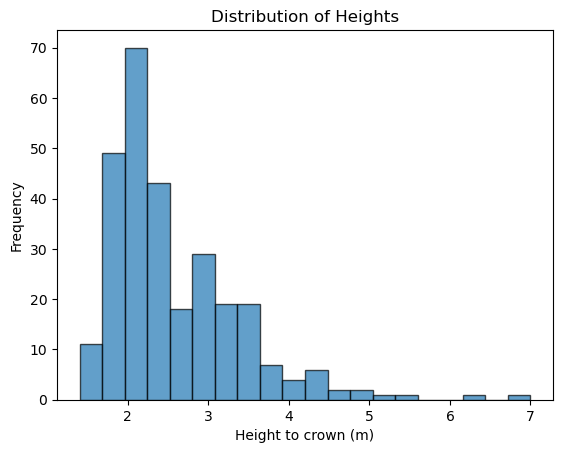

In [8]:
plt.hist(fieldwork_heights['hcb_m'], bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('Height to crown (m)')
plt.ylabel('Frequency')
plt.title('Distribution of Heights')
plt.show()

In [7]:
fieldwork_heights['hcb_m'].min()

np.float64(1.4)

The majority of heights to crown are around 2m, so if these heights are removed somes smaller branches will not be calculated, however considering the lower branches were generally directly under the higher branches on small trees, and the trees with diameters above 7.5cm start at 3.3m high, it is reasonable to start the mask at 2m. This reduces the need to seperate the identification of shrubs and trees as most shrubs were under 2m tall (field observation, not recorded)